# Supplemental Figure 7, panel E

Heatmaps at IFN-gamma gained-accessibility cREs (n = 548) showing:
- Nascent transcription level across all 4 conditions (Vehicle, IFN-gamma, BAFinh, BAFinh + IFN-gamma)
- Log2FC gain in accessibility in IFN-gamma vs vehicle, and suppression of accessibility gain by BAFinh pretreatment (log2FC accessibility, BAFinh+IFN-gamma vs IFN-gamma)
- Log2FC gain in nascent transcription in IFN-gamma vs vehicle, and suppression of transcription gain by BAFinh pretreatment (log2FC nascent transcription, BAFinh+IFN-gamma vs IFN-gamma)

*Outputs: PanelE.pdf*

# Setup

In [1]:
library(tidyverse)
library(rtracklayer)
library(pheatmap)
library(gridExtra)
library(here)
here::i_am("figures/SuppFig7/PanelE/PanelE.ipynb")
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           gridExtra_2.3        pheatmap_1.0.12     
 [4] rtracklayer_1.58.0   GenomicRanges_1.50.2 GenomeInfoDb_1.34.9 
 [7] IRanges_2.32.0       S4Vectors_0.36.2     BiocGenerics_0.44.0 
[10] lubridate_1.9.4      forcats_1.0.0        stringr_1.5.1       
[13] dpl

# load data

In [3]:
ifn_PRO <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/PROseq_eRNA/IFN_v_Veh_PROseq_cRE.tsv", sep='\t')
bafinh_ifn_PRO <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/PROseq_eRNA/BAFinh_IFN_v_IFN_PROseq_cRE.tsv", sep='\t')
#dREG_veh <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/veh/veh.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))
#dREG_ifn <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/ifn/ifn.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))
DAR_ifn <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_IFN_1h.tsv", sep='\t')
dREG_bafinh_ifn <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/bafinh_ifn/bafinh_ifn.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))
DAR_bafinh_ifn <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_BRM_IFN_1h.tsv", sep='\t')
counts <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/PROseq_eRNA/PROseq_cRE_counts.tsv", sep='\t')
log2_cpm <- apply(counts[,-1:-5],2,function(x) 1000000*x/sum(x)) %>% data.frame() %>% +1 %>% log2()

# Generate object for plotting

In [9]:
aggregated <- data.frame(
    ifn_PRO[,2:5], #cRE metadata
    PRO_lfc = ifn_PRO$log2FoldChange, #log2FC IFNg vs vehicle nascent transcription
    PRO_bafinh_lfc=bafinh_ifn_PRO$log2FoldChange,  #log2FC BAFinh+IFNg vs IFNg nascent transcription
    ATAC_lfc = DAR_ifn$logFC, #log2FC IFNg vs vehicle accessibility
    ATAC_bafinh_lfc=DAR_bafinh_ifn$logFC, #log2FC BAFinh+IFNg vs IFNg accessibility
    ATAC_change=DAR_ifn$change) # categorization of accessibility change (sig up, sig down, ns)

# Generate plots

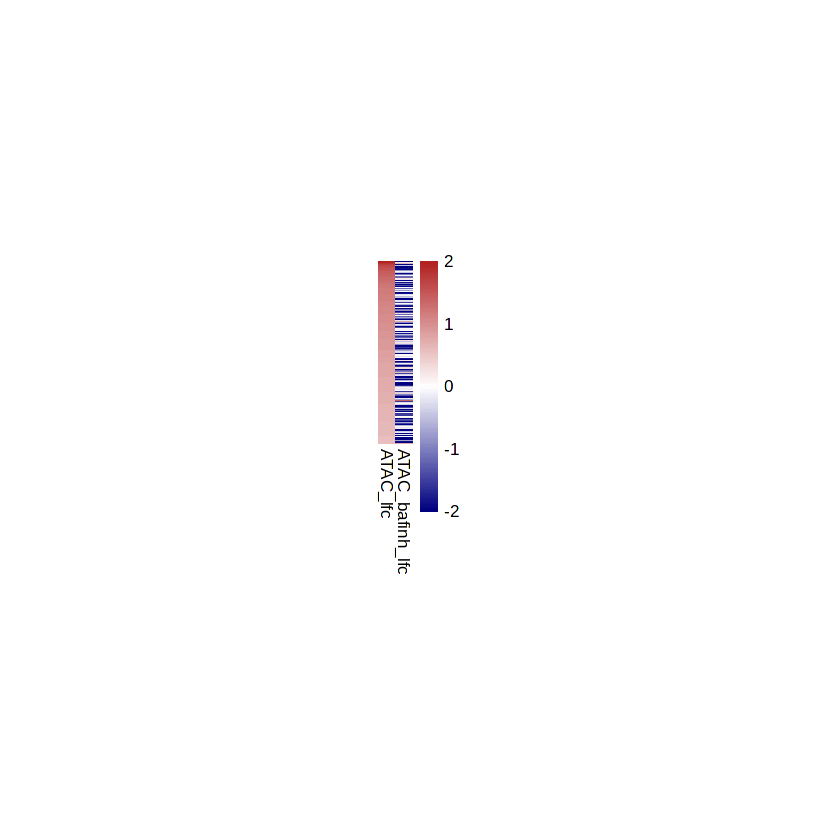

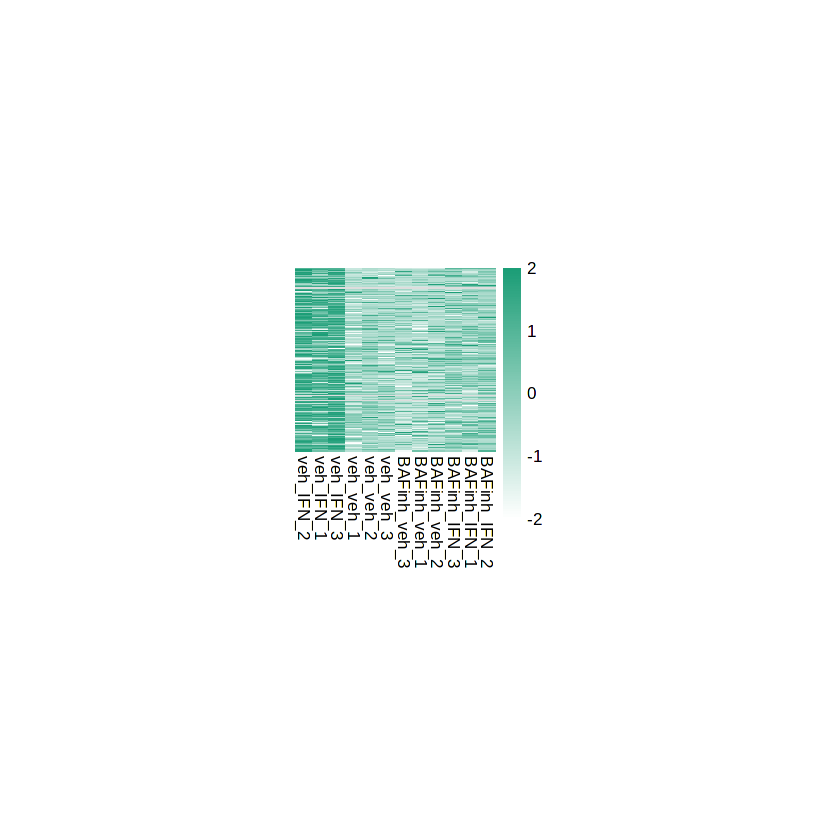

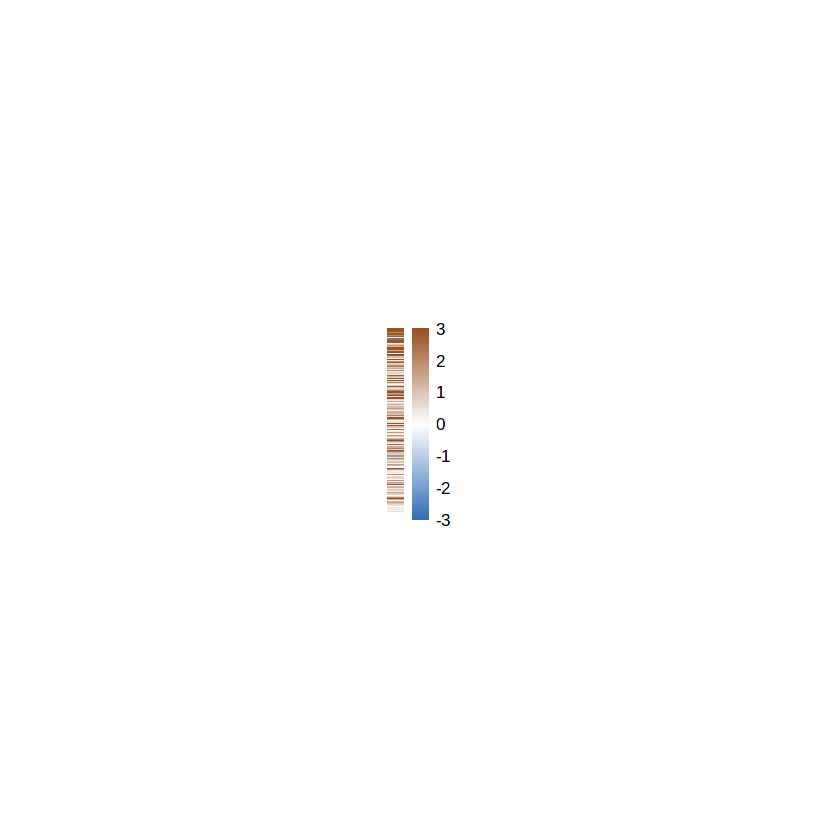

pdf 
  2

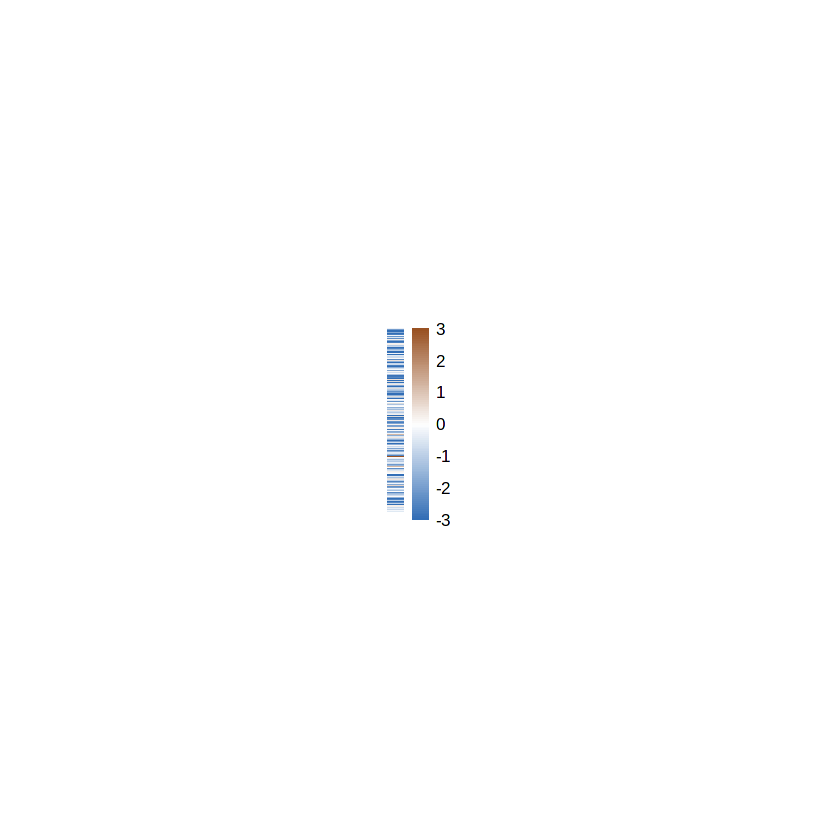

In [10]:
# select cREs that gain accessibility with IFN-g
ATAC_up <- which(aggregated$ATAC_change=="up" )
# order rows based on fold change IFN-gamma vs vehicle ATAC-seq
order <- order(aggregated[ATAC_up,"ATAC_lfc"], decreasing=T)

#ATAC-seq log2FC with IFN vs Veh and BAFinh+IFN vs IFN
p1 <- pheatmap(aggregated[ATAC_up,7:8][order,], 
         cluster_rows=F, 
         cluster_cols=F,
         col=colorRampPalette(colors=c("navy", "white", "firebrick"))(100),
         breaks=seq(-2,2,length.out=101), cellwidth=10, cellheight=.2, show_rownames=F)

#PRO-seq CPM
p2 <- pheatmap(log2_cpm[ATAC_up,][order,], 
         cluster_rows=F, 
         cluster_cols=T,
         col=colorRampPalette(colors=c("white", "#1c9e77"))(100),
         breaks=seq(-2,2,length.out=101),
         cellwidth=10, cellheight=.2, 
         show_rownames=F,
         treeheight_col=0, scale="row")

#PRO-seq log2FC, IFN vs Veh
p3 <- pheatmap(as.numeric(aggregated[ATAC_up,"PRO_lfc"][order]), 
         cluster_rows=F, 
         cluster_cols=F,
         breaks=seq(-3,3,length.out=101),
         colorRampPalette(colors=c("#326eb6","white", "#995223"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)

#PRO-seq log2FC, BAFinh+IFN vs IFN
p4 <- pheatmap(as.numeric(aggregated[ATAC_up,"PRO_bafinh_lfc"][order]), 
         cluster_rows=F, 
         cluster_cols=F,
         breaks=seq(-3,3,length.out=101),
         colorRampPalette(colors=c("#326eb6","white", "#995223"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)

pdf("PanelE.pdf", width=8.5)
grid.arrange(p1$gtable, p2$gtable, p3$gtable, p4$gtable, nrow=1)
dev.off()